# 04 — Phase 2, Experiment 1: combine-to-game capacity transfer (real data)

**Question.** How do an athlete's combine-40 speed and acceleration profile relate to the speed and acceleration they *express* in regular-season and postseason NFL games?

**Guardrails.**
- **Capacity is kept separate from execution, measurement uncertainty and performance.**
- No performance outcomes or career data are used. Exposure (plays) is used only as a nuisance and censoring variable.
- Combine capacity and game capacity are **not** assumed to be equal: correlation (ranking) and agreement (level) are reported separately.
- Identity: `nfl_id` matching was verified in Phase 1 (7 independent checks).

Pipeline: `scripts/run_real_capacity.py`.
- Game data: REG + POST; faulty game plays and speed spikes excluded.
- Kinematics: Savitzky–Golay, window 7.
- SIMEX noise SD: 0.01 yd (the real-noise calibration from Phase 1.6).

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src")); warnings.filterwarnings("ignore")
import numpy as np, polars as pl, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from nfl_bdb.visualization import style
from nfl_bdb.data.io import load
style.apply(); pl.Config.set_tbl_rows(80); pl.Config.set_tbl_width_chars(220); pl.Config.set_tbl_hide_dataframe_shape(True)
FIG = ROOT / "reports" / "figures"
def save(fig, name): fig.savefig(FIG / f"real_cap_{name}.png", bbox_inches="tight", dpi=150)
run = (ROOT / "experiments/real_capacity/LATEST").read_text().strip(); RD = ROOT / f"experiments/real_capacity/{run}"
F = pl.read_parquet(RD / "combine_forty_attempts.parquet"); G = pl.read_parquet(RD / "game_capacity.parquet")
print("run", run, "| exclusions:", json.load(open(RD / "exclusions.json")))
pos = load("combine_results", lazy=False).select("nfl_id", pl.col("combine_position").alias("pos"))
POS = style.POSITION_ORDER; PCOL = style.POSITION_COLOR
rng = np.random.default_rng(0)
def boot_r(x, y, f=lambda a,b: spearmanr(a,b).statistic, B=2000):
    x, y = np.asarray(x, float), np.asarray(y, float); ok = np.isfinite(x) & np.isfinite(y); x, y = x[ok], y[ok]
    if len(x) < 8: return (np.nan, np.nan, np.nan, len(x))
    est = f(x, y); bs = []
    for _ in range(B):
        i = rng.integers(0, len(x), len(x)); bs.append(f(x[i], y[i]))
    lo, hi = np.nanpercentile(bs, [2.5, 97.5]); return (est, lo, hi, len(x))

run 20261120T230324Z | exclusions: {'sequences_loaded': 264152, 'removed_faulty_game': 7, 'removed_speed_spike': 3, 'sequences_kept': 264142}


## 1 · Matching coverage and sample sizes

In [2]:
best = (F.drop_nulls("S0").sort("vpeak", descending=True).group_by("nfl_id").first()
        .select("nfl_id", pl.col("vpeak").alias("c_vpeak"), pl.col("S0").alias("c_S0"), pl.col("A0").alias("c_A0"), pl.col("tau").alias("c_tau"), pl.col("r2").alias("c_r2")))
GA = G.filter(pl.col("scope") == "all")
cov = (pos.join(best.select("nfl_id", pl.lit(1).alias("has40")), on="nfl_id", how="left")
       .join(GA.select("nfl_id", "n_plays"), on="nfl_id", how="left").fill_null(0))
tab = cov.group_by("pos").agg(pl.len().alias("combine_participants"), (pl.col("has40") == 1).sum().alias("with_40_tracking"),
        (pl.col("n_plays") > 0).sum().alias("with_game_tracking"),
        ((pl.col("has40") == 1) & (pl.col("n_plays") > 0)).sum().alias("both"),
        ((pl.col("has40") == 1) & (pl.col("n_plays") >= 50)).sum().alias("both_ge50plays"),
        ((pl.col("has40") == 1) & (pl.col("n_plays") >= 100)).sum().alias("both_ge100plays"),
        ((pl.col("has40") == 1) & (pl.col("n_plays") >= 300)).sum().alias("both_ge300plays")).sort("pos")
pl.concat([tab, tab.select(pl.lit("ALL").alias("pos"), *[pl.col(c).sum() for c in tab.columns[1:]])])

pos,combine_participants,with_40_tracking,with_game_tracking,both,both_ge50plays,both_ge100plays,both_ge300plays
str,u32,u32,u32,u32,u32,u32,u32
"""DB""",122,102,96,81,68,63,53
"""DL""",118,93,98,77,70,61,39
"""OL""",121,95,91,73,63,57,50
"""TE""",42,34,33,28,20,19,8
"""WR""",107,94,84,74,64,57,37
"""ALL""",510,418,402,333,285,257,187


Game exposure is REG + POST player-plays across 2023–25.
- WR/TE plays are route-running dropbacks only (Phase 1).
- 88 combine participants have no tracked 40 (they skipped the drill), so they cannot enter any transfer analysis.

## 2 · Combine-40 profiles and their two-attempt reliability

In [3]:
print(f"40-yd attempts: {F.height}; fitted: {F['S0'].is_not_null().sum()}; median R² = {F['r2'].median():.4f}")
two = F.drop_nulls("S0").group_by("nfl_id").agg(pl.len().alias("k"), pl.col("vpeak").sort_by("attempt").alias("vp"), pl.col("S0").sort_by("attempt").alias("S0s"), pl.col("A0").sort_by("attempt").alias("A0s"), pl.col("tau").sort_by("attempt").alias("taus")).filter(pl.col("k") == 2)
rows=[]
for m in ("vp","S0s","A0s","taus"):
    a=np.array([v[0] for v in two[m]]); b=np.array([v[1] for v in two[m]])
    r,lo,hi,n=boot_r(a,b,f=lambda u,v: pearsonr(u,v).statistic)
    te=np.std(b-a,ddof=1)/np.sqrt(2)
    rows.append(dict(measure={"vp":"peak speed","S0s":"S0 (fit)","A0s":"A0 (fit)","taus":"tau"}[m], n_players=n, test_retest_r=round(r,3), CI95=f"[{lo:.3f}, {hi:.3f}]", typical_error=round(te,3), TE_pct_of_mean=round(100*te/np.mean(np.r_[a,b]),2)))
pl.DataFrame(rows)

40-yd attempts: 793; fitted: 792; median R² = 0.9956


measure,n_players,test_retest_r,CI95,typical_error,TE_pct_of_mean
str,i64,f64,str,f64,f64
"""peak speed""",374,0.987,"""[0.984, 0.989]""",0.09,0.87
"""S0 (fit)""",374,0.934,"""[0.905, 0.957]""",0.236,2.18
"""A0 (fit)""",374,0.454,"""[0.331, 0.631]""",0.935,11.24
"""tau""",374,0.364,"""[0.259, 0.495]""",0.157,11.82


Two attempts on the same day are the only repeatability evidence the combine offers.
- This is within-session reliability, so it is optimistic: no between-day variation.
- The typical error is the SD of attempt differences divided by √2 (Hopkins 2000).

In [4]:
cb = best.join(pos, on="nfl_id")
cb.group_by("pos").agg(pl.len().alias("n"), *[pl.col(c).median().round(2).alias(c + "_median") for c in ("c_vpeak","c_S0","c_A0","c_tau")]).sort("pos")

pos,n,c_vpeak_median,c_S0_median,c_A0_median,c_tau_median
str,u32,f64,f64,f64,f64
"""DB""",102,11.02,11.53,8.69,1.32
"""DL""",93,10.21,10.51,8.04,1.32
"""OL""",95,9.41,9.71,7.31,1.34
"""TE""",34,10.48,10.9,8.13,1.33
"""WR""",94,11.09,11.6,8.68,1.33


## 3 · Game capacity measures: plausibility and split-half reliability

In [5]:
GA2 = GA.join(pos, on="nfl_id")
flags = GA2.select(pl.len().alias("players"),
    (pl.col("n_plays") < 10).sum().alias("lt10_plays_no_fit"),
    (pl.col("A0_bin") > 15).sum().alias("A0_bin_gt15_implausible"), (pl.col("A0_simex") > 15).sum().alias("A0_simex_gt15"),
    (pl.col("S0_bin") > 14).sum().alias("S0_bin_gt14"), (pl.col("S0_simex") > 14).sum().alias("S0_simex_gt14"),
    (pl.col("S0_simex") < pl.col("vmax_obs")).sum().alias("S0_simex_below_observed_max"))
flags

players,lt10_plays_no_fit,A0_bin_gt15_implausible,A0_simex_gt15,S0_bin_gt14,S0_simex_gt14,S0_simex_below_observed_max
u32,u32,u32,u32,u32,u32,u32
402,15,57,53,20,18,36


In [6]:
print("A0 > 15 yd/s² by exposure:", GA2.with_columns(pl.col("n_plays").cut([50,100,300]).alias("plays_bin")).group_by("plays_bin").agg(pl.len(), (pl.col("A0_bin")>15).mean().round(3).alias("frac_A0bin_gt15"), pl.col("A0_bin").median().round(2)).sort("plays_bin"))

A0 > 15 yd/s² by exposure: ┌────────────┬─────┬─────────────────┬────────┐
│ plays_bin  ┆ len ┆ frac_A0bin_gt15 ┆ A0_bin │
│ ---        ┆ --- ┆ ---             ┆ ---    │
│ enum       ┆ u32 ┆ f64             ┆ f64    │
╞════════════╪═════╪═════════════════╪════════╡
│ (-inf, 50] ┆ 67  ┆ 0.0             ┆ 8.62   │
│ (50, 100]  ┆ 28  ┆ 0.071           ┆ 8.45   │
│ (100, 300] ┆ 77  ┆ 0.052           ┆ 9.43   │
│ (300, inf] ┆ 230 ┆ 0.222           ┆ 10.15  │
└────────────┴─────┴─────────────────┴────────┘


**Implausible A0.**
- Binning extrapolates the A–S line to v = 0. For players with few high-effort efforts the slope is poorly determined, and A0 can exceed 15 yd/s² (13.7 m/s²), which is not credible.
- **Contrary to what we expected from Phase 1.6, they are concentrated at HIGH exposure** (table above). More frames give more chances for noise to inflate the maximum acceleration in the low-speed bins, which raises the extrapolated intercept.
- This is a real-data failure mode of binning for A0, so game A0 is treated as unreliable in what follows.

In [7]:
H = G.filter(pl.col("scope").is_in(["0","1"])).pivot(on="scope", index="nfl_id", values=["n_plays","vmax_obs","vmax_2nd","vmax_top5_mean","S0_bin","A0_bin","S0_simex","A0_simex"])
H = H.join(GA.select("nfl_id", pl.col("n_plays").alias("plays_all")), on="nfl_id")
rel=[]
for lo_,hi_,lab in [(20,100,"20–99 plays"),(100,300,"100–299"),(300,99999,"≥300")]:
    h=H.filter((pl.col("plays_all")>=lo_)&(pl.col("plays_all")<hi_))
    for m in ["vmax_obs","vmax_2nd","vmax_top5_mean","S0_bin","S0_simex","A0_bin","A0_simex"]:
        r,lo,hi,n=boot_r(h[f"{m}_0"],h[f"{m}_1"])
        rel.append(dict(exposure=lab, measure=m, n=n, split_half_rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]", spearman_brown=round(2*r/(1+r),3) if np.isfinite(r) else np.nan))
REL=pl.DataFrame(rel); REL.pivot(on="exposure", index="measure", values="spearman_brown")

measure,20–99 plays,100–299,≥300
str,f64,f64,f64
"""vmax_obs""",0.873,0.913,0.95
"""vmax_2nd""",0.842,0.954,0.967
"""vmax_top5_mean""",0.857,0.969,0.978
"""S0_bin""",0.783,0.82,0.803
"""S0_simex""",0.731,0.796,0.787
"""A0_bin""",0.666,0.691,0.829
"""A0_simex""",0.535,0.615,0.811


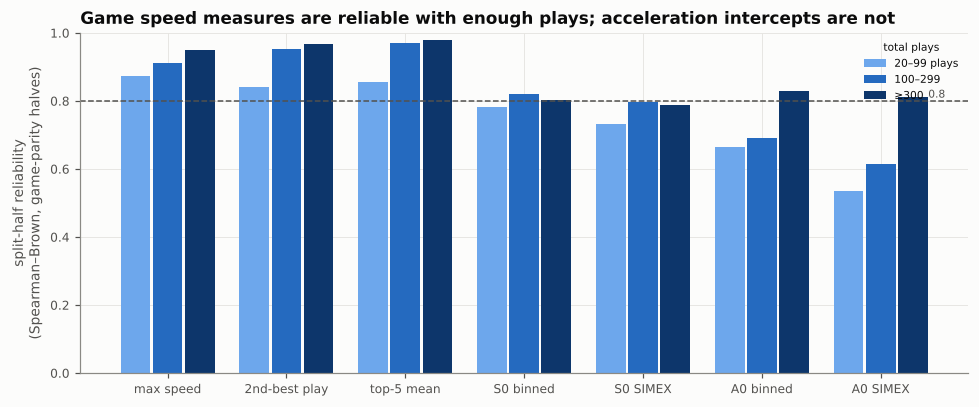

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ms=["vmax_obs","vmax_2nd","vmax_top5_mean","S0_bin","S0_simex","A0_bin","A0_simex"]; ex=["20–99 plays","100–299","≥300"]
for i,e in enumerate(ex):
    q=REL.filter(pl.col("exposure")==e)
    v=[q.filter(pl.col("measure")==m)["spearman_brown"][0] for m in ms]
    ax.bar(np.arange(len(ms))+(i-1)*0.27, v, width=0.25, color=style.SEQ_BLUE[2+2*i], label=e)
ax.set_xticks(range(len(ms)), ["max speed","2nd-best play","top-5 mean","S0 binned","S0 SIMEX","A0 binned","A0 SIMEX"], fontsize=8)
ax.axhline(0.8,color=style.TEXT2,ls="--",lw=1); ax.text(6.4,0.81,"0.8",fontsize=7,color=style.TEXT2)
ax.set_ylabel("split-half reliability\n(Spearman–Brown, game-parity halves)"); ax.set_ylim(0,1); ax.legend(fontsize=7, title="total plays", title_fontsize=7)
ax.set_title("Game speed measures are reliable with enough plays; acceleration intercepts are not", loc="left")
fig.tight_layout(); save(fig, "reliability")

## 4 · Transfer: rank correlation between combine and game measures

In [9]:
D = best.join(GA.select("nfl_id","n_plays","vmax_obs","vmax_2nd","vmax_top5_mean","S0_bin","A0_bin","S0_simex","A0_simex","se_logS0_simex","se_logA0_simex"), on="nfl_id").join(pos, on="nfl_id")
MAIN = D.filter(pl.col("n_plays") >= 100)
pairs=[("c_vpeak","vmax_obs"),("c_vpeak","vmax_top5_mean"),("c_S0","S0_simex"),("c_S0","S0_bin"),("c_A0","A0_bin"),("c_A0","A0_simex"),("c_tau","A0_bin")]
rows=[]
for grp in ["ALL (pooled)"]+POS:
    d = MAIN if grp.startswith("ALL") else MAIN.filter(pl.col("pos")==grp)
    for a,b in pairs:
        r,lo,hi,n=boot_r(d[a],d[b]); rows.append(dict(group=grp, combine=a, game=b, n=n, rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"))
T=pl.DataFrame(rows); T.pivot(on="group", index=["combine","game"], values="rho")

combine,game,ALL (pooled),WR,TE,OL,DL,DB
str,str,f64,f64,f64,f64,f64,f64
"""c_vpeak""","""vmax_obs""",0.853,0.585,0.684,0.381,0.734,0.132
"""c_vpeak""","""vmax_top5_mean""",0.871,0.554,0.589,0.352,0.737,0.224
"""c_S0""","""S0_simex""",0.671,0.147,0.364,0.334,0.395,0.226
"""c_S0""","""S0_bin""",0.702,0.174,0.455,0.348,0.481,0.247
"""c_A0""","""A0_bin""",0.406,0.193,0.428,-0.051,0.077,0.157
"""c_A0""","""A0_simex""",0.388,0.2,0.455,-0.128,0.061,0.158
"""c_tau""","""A0_bin""",-0.045,-0.179,-0.393,-0.008,0.127,-0.229


In [10]:
T.filter(pl.col("game").is_in(["vmax_obs","S0_simex","A0_bin"]))

group,combine,game,n,rho,CI95
str,str,str,i64,f64,str
"""ALL (pooled)""","""c_vpeak""","""vmax_obs""",257,0.853,"""[0.81, 0.88]"""
"""ALL (pooled)""","""c_S0""","""S0_simex""",254,0.671,"""[0.59, 0.73]"""
"""ALL (pooled)""","""c_A0""","""A0_bin""",254,0.406,"""[0.30, 0.50]"""
"""ALL (pooled)""","""c_tau""","""A0_bin""",254,-0.045,"""[-0.17, 0.07]"""
"""WR""","""c_vpeak""","""vmax_obs""",57,0.585,"""[0.37, 0.74]"""
"""WR""","""c_S0""","""S0_simex""",55,0.147,"""[-0.11, 0.38]"""
"""WR""","""c_A0""","""A0_bin""",55,0.193,"""[-0.09, 0.43]"""
"""WR""","""c_tau""","""A0_bin""",55,-0.179,"""[-0.42, 0.09]"""
"""TE""","""c_vpeak""","""vmax_obs""",19,0.684,"""[0.30, 0.88]"""


- **Pooled correlations are inflated by position composition**: OL are slow in both settings.
- **Within-position correlations are the relevant transfer estimates**; n per position is 54–72 with ≥ 100 plays (TE fewer).

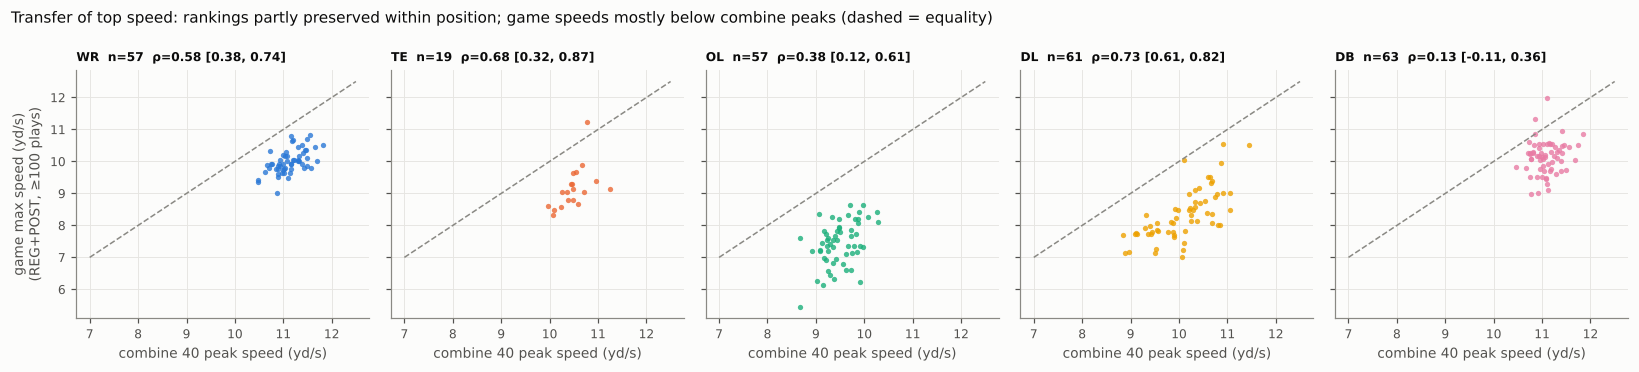

In [11]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True, sharey=True)
for ax, p in zip(axes, POS):
    d = MAIN.filter(pl.col("pos")==p)
    ax.scatter(d["c_vpeak"], d["vmax_obs"], s=12, color=PCOL[p], alpha=.8, linewidths=0)
    ax.plot([7,12.5],[7,12.5], color=style.MUTED, ls="--", lw=1)
    r,lo,hi,n=boot_r(d["c_vpeak"], d["vmax_obs"])
    ax.set_title(f"{p}  n={n}  ρ={r:.2f} [{lo:.2f}, {hi:.2f}]", fontsize=8, loc="left"); ax.set_xlabel("combine 40 peak speed (yd/s)")
axes[0].set_ylabel("game max speed (yd/s)\n(REG+POST, ≥100 plays)")
fig.suptitle("Transfer of top speed: rankings partly preserved within position; game speeds mostly below combine peaks (dashed = equality)", x=.01, ha="left", fontsize=10)
fig.tight_layout(); save(fig, "speed_transfer")

### 4.1 Correction for measurement unreliability (disattenuation)
ρ_true ≈ ρ_obs / √(rel_combine × rel_game).
- Combine reliability comes from the two-attempt correlation (pooled; within-session, so optimistic).
- Game reliability is the split-half Spearman–Brown value for the matching exposure stratum.
- Values above 1 indicate that the reliability inputs are too low or noisy. They are reported, not truncated.

In [12]:
rc = {"c_vpeak": pl.DataFrame(rows).height}  # placeholder to keep namespace tidy
rel_c = {}
for m,k in [("c_vpeak","vp"),("c_S0","S0s"),("c_A0","A0s")]:
    a=np.array([v[0] for v in two[k]]); b=np.array([v[1] for v in two[k]]); rel_c[m]=spearmanr(a,b).statistic
rel_g = {m: float(np.nanmean([REL.filter((pl.col("measure")==m)&(pl.col("exposure")==e))["spearman_brown"][0] for e in ("100–299","≥300")])) for m in ["vmax_obs","S0_simex","A0_bin"]}
out=[]
for grp in POS:
    for a,b in [("c_vpeak","vmax_obs"),("c_S0","S0_simex"),("c_A0","A0_bin")]:
        q=T.filter((pl.col("group")==grp)&(pl.col("combine")==a)&(pl.col("game")==b))
        r=q["rho"][0]; den=np.sqrt(rel_c[a]*rel_g[b])
        out.append(dict(position=grp, pair=f"{a} ↔ {b}", rho_obs=r, rel_combine=round(rel_c[a],3), rel_game=round(rel_g[b],3), rho_disattenuated=round(r/den,3)))
pl.DataFrame(out)

position,pair,rho_obs,rel_combine,rel_game,rho_disattenuated
str,str,f64,f64,f64,f64
"""WR""","""c_vpeak ↔ vmax_obs""",0.585,0.981,0.931,0.612
"""WR""","""c_S0 ↔ S0_simex""",0.147,0.939,0.792,0.17
"""WR""","""c_A0 ↔ A0_bin""",0.193,0.652,0.76,0.274
"""TE""","""c_vpeak ↔ vmax_obs""",0.684,0.981,0.931,0.716
"""TE""","""c_S0 ↔ S0_simex""",0.364,0.939,0.792,0.422
"""TE""","""c_A0 ↔ A0_bin""",0.428,0.652,0.76,0.608
"""OL""","""c_vpeak ↔ vmax_obs""",0.381,0.981,0.931,0.399
"""OL""","""c_S0 ↔ S0_simex""",0.334,0.939,0.792,0.387
"""OL""","""c_A0 ↔ A0_bin""",-0.051,0.652,0.76,-0.072


## 5 · Agreement (level), not just ranking: game minus combine

In [13]:
ag = MAIN.with_columns((pl.col("vmax_obs")-pl.col("c_vpeak")).alias("d_vmax"), (pl.col("S0_simex")-pl.col("c_S0")).alias("d_S0"),
                       (pl.col("vmax_obs")/pl.col("c_vpeak")).alias("ratio_vmax"))
summ = ag.group_by("pos").agg(pl.len().alias("n"), pl.col("d_vmax").mean().round(2).alias("mean_game_minus_combine_vmax"),
        (1.96*pl.col("d_vmax").std()).round(2).alias("LoA_half_width"), pl.col("ratio_vmax").median().round(3).alias("median_ratio"),
        (pl.col("ratio_vmax")>1).mean().round(3).alias("share_exceeding_combine_peak"),
        pl.col("d_S0").drop_nans().mean().round(2).alias("mean_S0_game_minus_combine")).sort("pos")
summ

pos,n,mean_game_minus_combine_vmax,LoA_half_width,median_ratio,share_exceeding_combine_peak,mean_S0_game_minus_combine
str,u32,f64,f64,f64,f64,f64
"""DB""",63,-0.95,1.07,0.917,0.032,-0.69
"""DL""",61,-1.75,1.14,0.827,0.0,-0.71
"""OL""",57,-2.05,1.23,0.798,0.0,-0.9
"""TE""",19,-1.32,1.1,0.865,0.053,-1.16
"""WR""",57,-1.12,0.63,0.898,0.0,-0.09


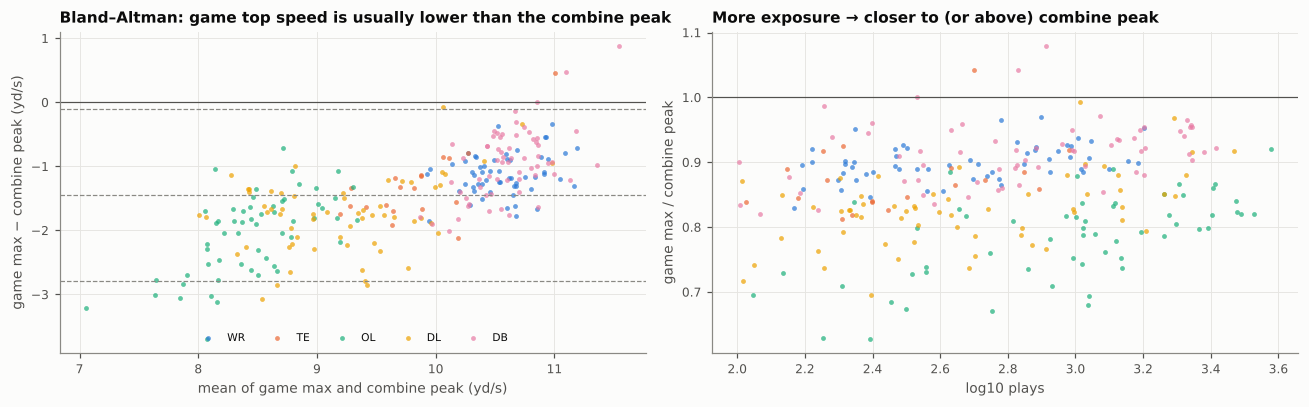

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for p in POS:
    d=ag.filter(pl.col("pos")==p)
    axes[0].scatter((d["vmax_obs"]+d["c_vpeak"])/2, d["d_vmax"], s=10, color=PCOL[p], alpha=.7, linewidths=0, label=p)
axes[0].axhline(0,color=style.TEXT2,lw=.8); m=ag["d_vmax"].mean(); sd=ag["d_vmax"].std()
for v in (m, m-1.96*sd, m+1.96*sd): axes[0].axhline(v, color=style.MUTED, ls="--", lw=.8)
axes[0].set_xlabel("mean of game max and combine peak (yd/s)"); axes[0].set_ylabel("game max − combine peak (yd/s)"); axes[0].legend(fontsize=7, ncol=5, loc="lower center")
axes[0].set_title("Bland–Altman: game top speed is usually lower than the combine peak", loc="left", fontsize=10)
lp=np.log10(ag["n_plays"].to_numpy())
for p in POS:
    d=ag.filter(pl.col("pos")==p); axes[1].scatter(np.log10(d["n_plays"]), d["ratio_vmax"], s=10, color=PCOL[p], alpha=.7, linewidths=0)
axes[1].axhline(1,color=style.TEXT2,lw=.8); axes[1].set_xlabel("log10 plays"); axes[1].set_ylabel("game max / combine peak")
axes[1].set_title("More exposure → closer to (or above) combine peak", loc="left", fontsize=10)
fig.tight_layout(); save(fig, "agreement")

## 6 · Exposure: how much game data is needed before transfer is visible?

In [15]:
E = D.filter(pl.col("n_plays") >= 10)
rows=[]
for lo_,hi_,lab in [(10,50,"10–49"),(50,100,"50–99"),(100,300,"100–299"),(300,99999,"≥300")]:
    for a,b in [("c_vpeak","vmax_obs"),("c_S0","S0_simex"),("c_A0","A0_bin")]:
        d=E.filter((pl.col("n_plays")>=lo_)&(pl.col("n_plays")<hi_))
        # within-position: rank-transform within position, then pool
        d=d.with_columns(pl.col(a).rank().over("pos").alias("ra"), pl.col(b).rank().over("pos").alias("rb"), pl.len().over("pos").alias("np_"))
        d=d.with_columns((pl.col("ra")/pl.col("np_")).alias("ra"), (pl.col("rb")/pl.col("np_")).alias("rb"))
        r,lo,hi,n=boot_r(d["ra"],d["rb"]); rows.append(dict(plays=lab, pair=f"{a} ↔ {b}", n=n, within_position_rho=round(r,3), CI95=f"[{lo:.2f}, {hi:.2f}]"))
EX=pl.DataFrame(rows); EX

plays,pair,n,within_position_rho,CI95
str,str,i64,f64,str
"""10–49""","""c_vpeak ↔ vmax_obs""",38,0.063,"""[-0.27, 0.39]"""
"""10–49""","""c_S0 ↔ S0_simex""",38,0.078,"""[-0.31, 0.43]"""
"""10–49""","""c_A0 ↔ A0_bin""",38,-0.09,"""[-0.42, 0.23]"""
"""50–99""","""c_vpeak ↔ vmax_obs""",28,0.454,"""[0.10, 0.71]"""
"""50–99""","""c_S0 ↔ S0_simex""",28,0.207,"""[-0.20, 0.56]"""
"""50–99""","""c_A0 ↔ A0_bin""",28,-0.146,"""[-0.57, 0.25]"""
"""100–299""","""c_vpeak ↔ vmax_obs""",70,0.567,"""[0.39, 0.70]"""
"""100–299""","""c_S0 ↔ S0_simex""",70,0.263,"""[0.03, 0.46]"""
"""100–299""","""c_A0 ↔ A0_bin""",70,0.117,"""[-0.15, 0.35]"""


In [16]:
import statsmodels.formula.api as smf
reg = ag.select("ratio_vmax","n_plays","pos").to_pandas(); reg["log_plays"]=np.log10(reg["n_plays"])
fit = smf.ols("ratio_vmax ~ log_plays + C(pos)", data=reg).fit(cov_type="HC3")
print(fit.summary().tables[1])

                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.7278      0.026     28.045      0.000       0.677       0.779
C(pos)[T.DL]    -0.0778      0.009     -8.627      0.000      -0.096      -0.060
C(pos)[T.OL]    -0.1391      0.010    -14.377      0.000      -0.158      -0.120
C(pos)[T.TE]    -0.0172      0.014     -1.235      0.217      -0.045       0.010
C(pos)[T.WR]    -0.0039      0.007     -0.531      0.596      -0.018       0.011
log_plays        0.0660      0.009      7.700      0.000       0.049       0.083


This is a nuisance model: how much the game peak approaches the combine peak as exposure grows. Exposure is not an outcome here, and no performance variable enters.

## 7 · Individual differences

In [17]:
res=[]
for p in POS:
    d=MAIN.filter(pl.col("pos")==p).drop_nulls(["c_vpeak","vmax_obs"])
    if d.height<10: continue
    xx=d["c_vpeak"].to_numpy(); yy=d["vmax_obs"].to_numpy(); b1,b0=np.polyfit(xx,yy,1); r=yy-(b0+b1*xx)
    res.append(dict(pos=p, n=d.height, slope=round(b1,3), residual_sd_yds=round(float(np.std(r,ddof=2)),3),
                    combine_peak_sd=round(float(d["c_vpeak"].std()),3), game_max_sd=round(float(d["vmax_obs"].std()),3)))
pl.DataFrame(res)

pos,n,slope,residual_sd_yds,combine_peak_sd,game_max_sd
str,i64,f64,f64,f64,f64
"""WR""",57,0.691,0.312,0.301,0.373
"""TE""",19,1.096,0.576,0.311,0.656
"""OL""",57,0.825,0.631,0.359,0.692
"""DL""",61,0.907,0.583,0.616,0.804
"""DB""",63,0.326,0.519,0.276,0.523


- The residual SD measures how much players at the same combine speed differ in expressed game speed.
- This residual mixes role, exposure, measurement error and genuine "expression" differences. **It is not interpretable as execution or performance without further work.**

## 8 · Summary
See `research_notes/real_data_capacity_transfer.md`.